# Taller 08: Random Forest - Clasificación de dígitos (`sklearn.datasets.load_digits`)

## Solución
1. Dividir el dataset: **80 % entrenamiento / 20 % prueba**. El conjunto de prueba no se toca hasta el final.
2. Usar K-fold = 4 (`StratifiedKFold`) sobre el 80 % de entrenamiento para toda selección de hiperparámetros.
3. Estudiar el efecto del número de árboles (`n_estimators`).
4. Estudiar la poda de los árboles: poda por costo-complejidad (`ccp_alpha`) y, como comparación, pre-poda (`max_depth`, `min_samples_leaf`).
5. Búsqueda conjunta (`n_estimators` × `ccp_alpha`) con métricas de train y validación para detectar over-fitting.
6. Elegir el modelo con la regla de 1 error estándar (el más simple cuyo desempeño esté dentro de 1 SE del mejor).
7. Evaluar una sola vez en el conjunto de prueba.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import warnings; warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Datos y partición 80 % / 20 %

Forma de X: (1797, 64) | clases: [0 1 2 3 4 5 6 7 8 9]


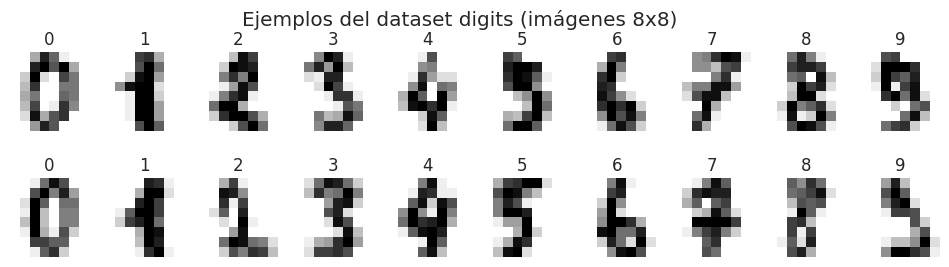

Entrenamiento: 1437 | Prueba: 360


In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Forma de X:", X.shape, "| clases:", np.unique(y))

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.suptitle("Ejemplos del dataset digits (imágenes 8x8)"); plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Entrenamiento: {X_train.shape[0]} | Prueba: {X_test.shape[0]}")

# K-fold = 4 para todo el proceso de entrenamiento/validación
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

## 2. Modelo base (sin poda, 100 árboles)
Sirve como referencia. Un árbol sin restricciones crece hasta que todas las hojas son puras, así que su exactitud en entrenamiento será ~100 % (señal típica de sobreajuste en árboles individuales).

In [3]:
def cv_scores(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy",
                       return_train_score=True, n_jobs=-1)
    return r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()

base = RandomForestClassifier(n_estimators=100, random_state=SEED)
tr, va, sd = cv_scores(base)
print(f"RF base  -> train: {tr:.4f} | validación (4-fold): {va:.4f} ± {sd:.4f} | brecha: {tr-va:.4f}")

base.fit(X_train, y_train)
n_nodes = np.mean([t.tree_.node_count for t in base.estimators_])
depth = np.mean([t.get_depth() for t in base.estimators_])
print(f"Tamaño medio de cada árbol: {n_nodes:.0f} nodos, profundidad media {depth:.1f}")

RF base  -> train: 1.0000 | validación (4-fold): 0.9722 ± 0.0028 | brecha: 0.0278


Tamaño medio de cada árbol: 340 nodos, profundidad media 13.3


## 3. ¿Cuántos árboles se necesitan?
Se varía `n_estimators` (árboles sin podar) y se mide exactitud de entrenamiento y de validación con 4-fold. Se espera que la validación se estabilice a partir de cierto número de árboles: más árboles ya no aportan.

,n_estimators,train,val,val_std
0,1,0.9102,0.7731,0.0208
1,2,0.9035,0.7551,0.0197
2,3,0.9717,0.8434,0.0103
3,5,0.9933,0.9005,0.0127
4,8,0.9988,0.9374,0.0109
5,10,0.9993,0.9408,0.0098
6,15,0.9995,0.9562,0.0093
7,20,1.0000,0.9638,0.0052
8,30,1.0000,0.9652,0.0050
9,50,1.0000,0.9673,0.0023


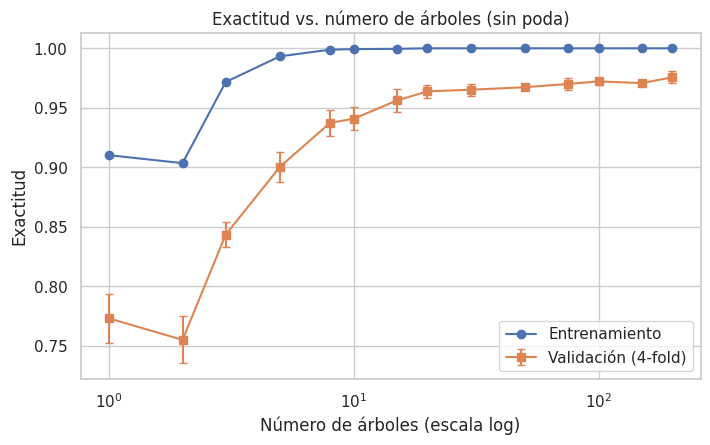

In [4]:
n_list = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200]
rows = []
for n in n_list:
    tr, va, sd = cv_scores(RandomForestClassifier(n_estimators=n, random_state=SEED))
    rows.append((n, tr, va, sd))
df_n = pd.DataFrame(rows, columns=["n_estimators", "train", "val", "val_std"])
display(df_n.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(df_n.n_estimators, df_n.train, "o-", label="Entrenamiento")
plt.errorbar(df_n.n_estimators, df_n.val, yerr=df_n.val_std, fmt="s-", capsize=3, label="Validación (4-fold)")
plt.xscale("log"); plt.xlabel("Número de árboles (escala log)"); plt.ylabel("Exactitud")
plt.title("Exactitud vs. número de árboles (sin poda)"); plt.legend(); plt.show()

## 4. Estrategia de poda: `ccp_alpha` (Cost-Complexity Pruning)

La poda por costo-complejidad minimiza

$$R_\alpha(T) = R(T) + \alpha\,|T|$$

donde $R(T)$ es el error de clasificación (impureza) de las hojas del árbol $T$, $|T|$ el número de hojas y $\alpha \ge 0$ la penalización por complejidad.

* Con $\alpha = 0$ no hay poda: el árbol crece completo.
* Al aumentar $\alpha$, se podan sucesivamente los subárboles cuyo "enlace más débil" (menor mejora de impureza por hoja añadida) cuesta menos que $\alpha$. El árbol se hace más pequeño.
* `DecisionTreeClassifier.cost_complexity_pruning_path` entrega la secuencia de valores efectivos de $\alpha$ y la impureza total de las hojas.

Uso en un Random Forest: `RandomForestClassifier(ccp_alpha=...)` aplica la misma poda a cada árbol del bosque. El resultado son árboles más pequeños (menos varianza individual) y un modelo más compacto.

### 4.1 Camino de poda sobre un árbol individual

Valores de alpha en el camino de poda: 123


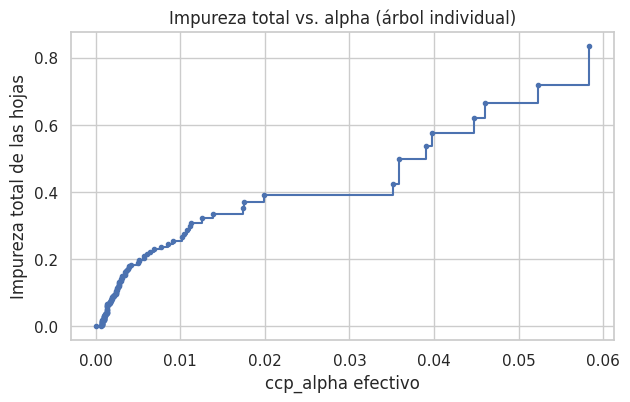

In [5]:
tree = DecisionTreeClassifier(random_state=SEED)
path = tree.cost_complexity_pruning_path(X_train, y_train)
alphas, impurities = path.ccp_alphas, path.impurities
print("Valores de alpha en el camino de poda:", len(alphas))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post", ms=3)
ax.set_xlabel("ccp_alpha efectivo"); ax.set_ylabel("Impureza total de las hojas")
ax.set_title("Impureza total vs. alpha (árbol individual)"); plt.show()

### 4.2 Exactitud y tamaño del árbol vs. `ccp_alpha` (árbol individual, 4-fold)
Se evalúa un subconjunto de valores de alpha del camino (el último, que deja solo la raíz, se descarta).

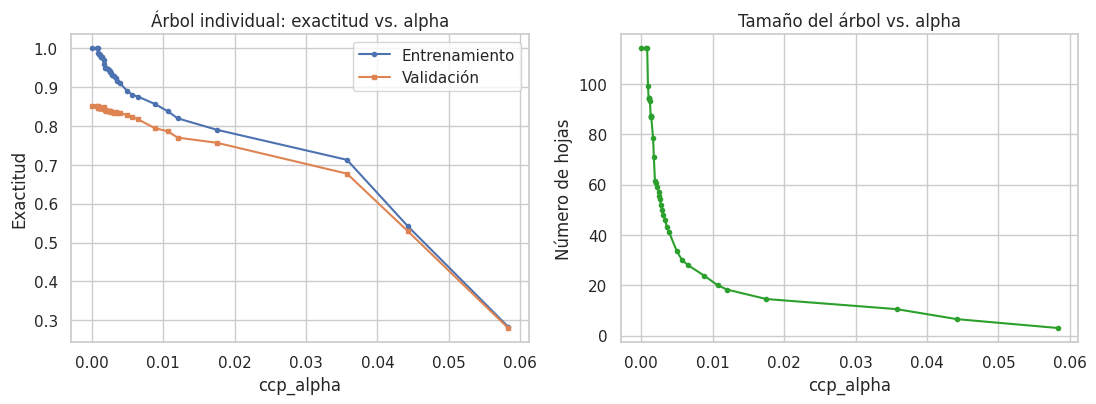

In [6]:
cand = np.unique(np.quantile(alphas[:-1], np.linspace(0, 1, 40)))
rows = []
for a in cand:
    t = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    r = cross_validate(t, X_train, y_train, cv=cv, return_train_score=True,
                       return_estimator=True, n_jobs=-1)
    leaves = np.mean([e.get_n_leaves() for e in r["estimator"]])
    rows.append((a, r["train_score"].mean(), r["test_score"].mean(), leaves))
df_t = pd.DataFrame(rows, columns=["ccp_alpha", "train", "val", "hojas"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df_t.ccp_alpha, df_t.train, "o-", ms=3, label="Entrenamiento")
ax[0].plot(df_t.ccp_alpha, df_t.val, "s-", ms=3, label="Validación")
ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("Exactitud"); ax[0].legend()
ax[0].set_title("Árbol individual: exactitud vs. alpha")
ax[1].plot(df_t.ccp_alpha, df_t.hojas, "o-", ms=3, color="tab:green")
ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("Número de hojas")
ax[1].set_title("Tamaño del árbol vs. alpha"); plt.show()

### 4.3 Efecto de `ccp_alpha` dentro de un Random Forest
Se fija un número generoso de árboles (100) y se varía `ccp_alpha` (rejilla más fina en valores pequeños, que es donde el árbol cambia). Se reporta también el **tamaño medio de cada árbol (nodos)**.

,ccp_alpha,train,val,val_std,nodos_por_arbol,brecha
0,0.0000,1.0000,0.9722,0.0028,277.715,0.0278
1,0.0005,1.0000,0.9722,0.0028,277.675,0.0278
2,0.0010,1.0000,0.9722,0.0034,244.575,0.0278
3,0.0020,0.9995,0.9687,0.0041,169.320,0.0309
4,0.0040,0.9954,0.9569,0.0057,102.540,0.0385
5,0.0060,0.9831,0.9513,0.0069,71.270,0.0318
6,0.0100,0.9615,0.9374,0.0041,43.660,0.0241
7,0.0150,0.9453,0.9242,0.0063,29.830,0.0211
8,0.0200,0.9311,0.9137,0.0071,22.345,0.0174
9,0.0300,0.9010,0.8817,0.0112,14.635,0.0193


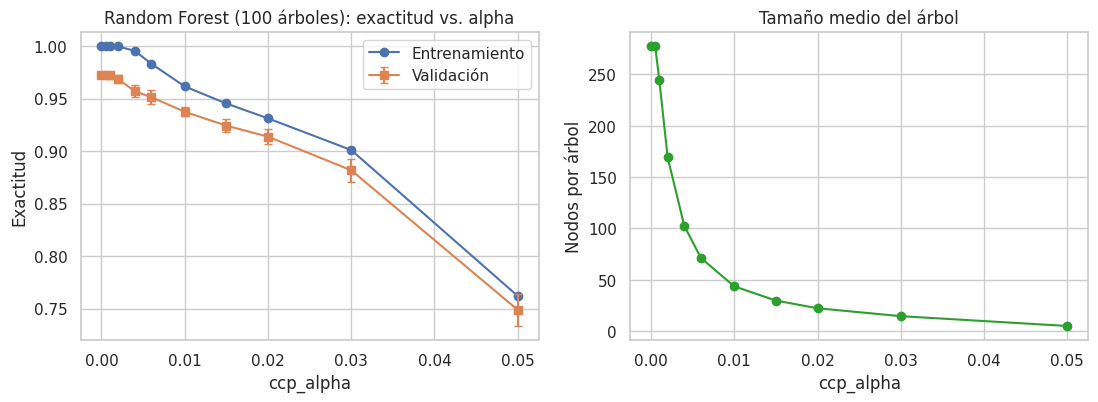

In [7]:
alpha_grid = [0, 0.0005, 0.001, 0.002, 0.004, 0.006, 0.01, 0.015, 0.02, 0.03, 0.05]
rows = []
for a in alpha_grid:
    rf = RandomForestClassifier(n_estimators=100, ccp_alpha=a, random_state=SEED)
    r = cross_validate(rf, X_train, y_train, cv=cv, return_train_score=True,
                       return_estimator=True, n_jobs=-1)
    nodes = np.mean([[t.tree_.node_count for t in e.estimators_] for e in r["estimator"]])
    rows.append((a, r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std(), nodes))
df_a = pd.DataFrame(rows, columns=["ccp_alpha", "train", "val", "val_std", "nodos_por_arbol"])
df_a["brecha"] = df_a.train - df_a.val
display(df_a.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df_a.ccp_alpha, df_a.train, "o-", label="Entrenamiento")
ax[0].errorbar(df_a.ccp_alpha, df_a.val, yerr=df_a.val_std, fmt="s-", capsize=3, label="Validación")
ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("Exactitud"); ax[0].legend()
ax[0].set_title("Random Forest (100 árboles): exactitud vs. alpha")
ax[1].plot(df_a.ccp_alpha, df_a.nodos_por_arbol, "o-", color="tab:green")
ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("Nodos por árbol")
ax[1].set_title("Tamaño medio del árbol"); plt.show()

### 4.4 Comparación con pre-poda (`max_depth`, `min_samples_leaf`)
Alternativa para *detener el crecimiento* durante la construcción. Se muestra solo como referencia: la estrategia principal es `ccp_alpha`.

In [8]:
rows = []
for d in [2, 3, 4, 5, 6, 8, 10, None]:
    tr, va, sd = cv_scores(RandomForestClassifier(n_estimators=100, max_depth=d, random_state=SEED))
    rows.append(("max_depth", d, tr, va))
for m in [1, 2, 3, 5, 8, 12]:
    tr, va, sd = cv_scores(RandomForestClassifier(n_estimators=100, min_samples_leaf=m, random_state=SEED))
    rows.append(("min_samples_leaf", m, tr, va))
display(pd.DataFrame(rows, columns=["parametro", "valor", "train", "val"]).round(4))

,parametro,valor,train,val
0,max_depth,2.0,0.8395,0.8212
1,max_depth,3.0,0.9049,0.8838
2,max_depth,4.0,0.9462,0.9193
3,max_depth,5.0,0.9738,0.9381
4,max_depth,6.0,0.9912,0.9555
5,max_depth,8.0,0.9993,0.9645
6,max_depth,10.0,1.0000,0.9715
7,max_depth,NaN,1.0000,0.9722
8,min_samples_leaf,1.0,1.0000,0.9722
9,min_samples_leaf,2.0,1.0000,0.9722


## 5. Búsqueda conjunta: `n_estimators` × `ccp_alpha` (GridSearchCV, 4-fold)
Se guardan las métricas de entrenamiento y validación para cuantificar el over-fitting (brecha) y se calcula el tamaño de los árboles de cada configuración.

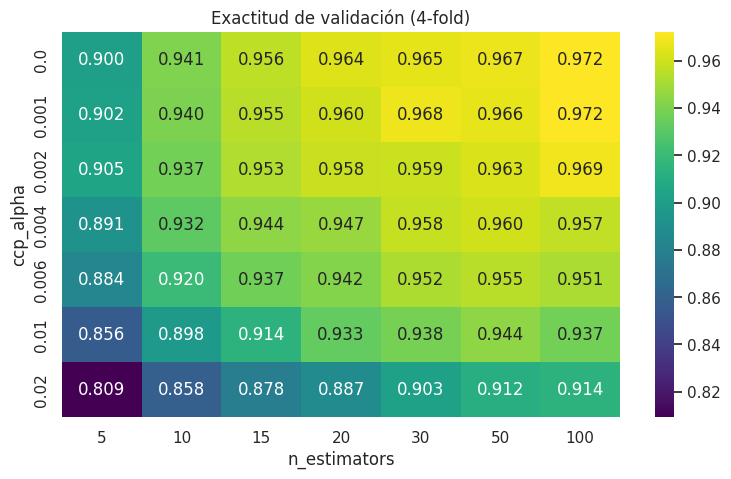

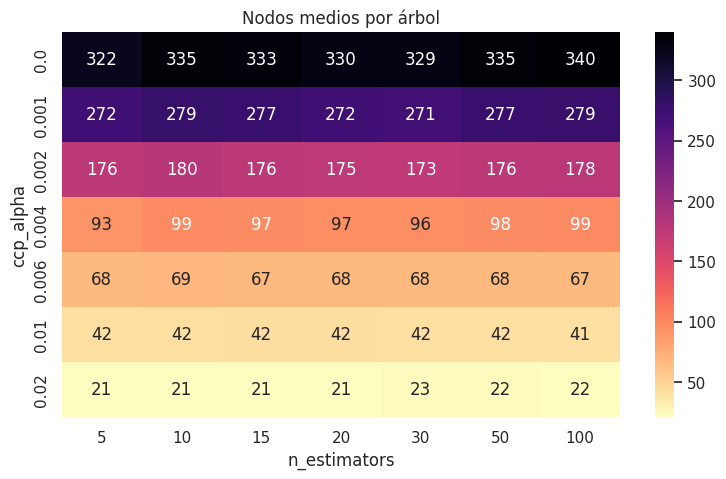

Mejor configuración (solo exactitud): {'ccp_alpha': 0, 'n_estimators': 100} -> 0.9722


In [9]:
param_grid = {
    "n_estimators": [5, 10, 15, 20, 30, 50, 100],
    "ccp_alpha": [0, 0.001, 0.002, 0.004, 0.006, 0.01, 0.02],
}
gs = GridSearchCV(RandomForestClassifier(random_state=SEED), param_grid,
                  cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)
gs.fit(X_train, y_train)

res = pd.DataFrame(gs.cv_results_)[[
    "param_n_estimators", "param_ccp_alpha", "mean_train_score",
    "mean_test_score", "std_test_score"]]
res.columns = ["n_estimators", "ccp_alpha", "train", "val", "val_std"]
res = res.astype({"n_estimators": int, "ccp_alpha": float})
res["brecha"] = res.train - res.val

# Tamaño medio de árbol por configuración (ajuste en todo el train)
def avg_nodes(n, a):
    m = RandomForestClassifier(n_estimators=n, ccp_alpha=a, random_state=SEED).fit(X_train, y_train)
    return np.mean([t.tree_.node_count for t in m.estimators_])
res["nodos"] = [avg_nodes(n, a) for n, a in zip(res.n_estimators, res.ccp_alpha)]

pivot = res.pivot(index="ccp_alpha", columns="n_estimators", values="val")
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Exactitud de validación (4-fold)"); plt.show()

pivot_n = res.pivot(index="ccp_alpha", columns="n_estimators", values="nodos")
plt.figure(figsize=(9, 5))
sns.heatmap(pivot_n, annot=True, fmt=".0f", cmap="magma_r")
plt.title("Nodos medios por árbol"); plt.show()

print("Mejor configuración (solo exactitud):", gs.best_params_, f"-> {gs.best_score_:.4f}")

## 6. Selección: mínimo de árboles y menor tamaño sin over-fitting
Criterio de equivalencia práctica con tolerancia $\tau$:

1. Se toma la mejor exactitud de validación $V^*$ de toda la rejilla.
2. Se conservan las configuraciones con $V \ge V^* - \tau$ (rendimiento prácticamente igual al mejor). Se usa $\tau = 1.5$ puntos porcentuales; abajo se muestra la sensibilidad a este valor.
3. De ellas se elige la que tenga menos árboles; a igualdad, menos nodos por árbol (árboles más pequeños).
4. Se verifica la brecha train–validación y la curva OOB. En un Random Forest la exactitud de entrenamiento suele ser ≈ 1 aun cuando el modelo generaliza bien (cada árbol ve una muestra bootstrap y el voto promedia errores), por lo que lo decisivo es que la validación sea estable, que el OOB concuerde y que la prueba final sea consistente.

Nota: la regla clásica de 1 error estándar es aquí demasiado estricta, porque la desviación entre folds es muy pequeña (~0.3 pp) y obligaría a usar 100 árboles.

In [10]:
TOL = 0.015
best = res.loc[res.val.idxmax()]
print(f"Mejor val = {best.val:.4f}  (n_estimators={int(best.n_estimators)}, ccp_alpha={best.ccp_alpha})")

# Sensibilidad a la tolerancia
sens = []
for tol in [0.005, 0.010, 0.015, 0.020, 0.030]:
    c = res[res.val >= best.val - tol].sort_values(["n_estimators", "nodos"]).iloc[0]
    sens.append((tol, int(c.n_estimators), c.ccp_alpha, c.val, c.brecha, c.nodos))
display(pd.DataFrame(sens, columns=["tolerancia", "n_estimators", "ccp_alpha", "val", "brecha", "nodos/árbol"]).round(4))

cands = res[res.val >= best.val - TOL].sort_values(["n_estimators", "nodos"])
print("\nCandidatos con tolerancia", TOL)
display(cands.head(8).round(4))

chosen = cands.iloc[0]
N_OPT, A_OPT = int(chosen.n_estimators), float(chosen.ccp_alpha)
print(f"\n>>> Configuración elegida: n_estimators = {N_OPT}, ccp_alpha = {A_OPT}")
print(f"    val = {chosen.val:.4f} | train = {chosen.train:.4f} | brecha = {chosen.brecha:.4f} | nodos/árbol ≈ {chosen.nodos:.0f}")

Mejor val = 0.9722  (n_estimators=100, ccp_alpha=0.0)


,tolerancia,n_estimators,ccp_alpha,val,brecha,nodos/árbol
0,0.005,30,0.001,0.9680,0.0320,271.4667
1,0.010,20,0.000,0.9638,0.0362,329.6000
2,0.015,20,0.002,0.9582,0.0399,175.0000
3,0.020,15,0.002,0.9527,0.0436,175.6667
4,0.030,15,0.004,0.9443,0.0415,97.2667



Candidatos con tolerancia 0.015


,n_estimators,ccp_alpha,train,val,val_std,brecha,nodos
17,20,0.002,0.9981,0.9582,0.0088,0.0399,175.0000
10,20,0.001,0.9998,0.9603,0.0064,0.0394,272.4000
3,20,0.000,1.0000,0.9638,0.0052,0.0362,329.6000
25,30,0.004,0.9903,0.9575,0.0054,0.0327,96.2000
18,30,0.002,0.9981,0.9589,0.0060,0.0392,173.4667
11,30,0.001,1.0000,0.9680,0.0014,0.0320,271.4667
4,30,0.000,1.0000,0.9652,0.0050,0.0348,328.8667
26,50,0.004,0.9930,0.9603,0.0023,0.0327,98.0800



>>> Configuración elegida: n_estimators = 20, ccp_alpha = 0.002
    val = 0.9582 | train = 0.9981 | brecha = 0.0399 | nodos/árbol ≈ 175


### 6.1 Verificación de ausencia de over-fitting: curva de validación con la poda elegida
Con `ccp_alpha` fijo en el valor elegido, se revisa que al aumentar los árboles la validación se estabilice (no baje) y también el error *out-of-bag* (OOB), una estimación independiente de generalización.

,n_estimators,train,val,oob
0,1,0.8720,0.7836,NaN
1,2,0.9023,0.7919,NaN
2,3,0.9601,0.8608,NaN
3,5,0.9831,0.9047,NaN
4,8,0.9919,0.9311,NaN
5,10,0.9930,0.9374,NaN
6,15,0.9963,0.9527,NaN
7,20,0.9981,0.9582,NaN
8,30,0.9981,0.9589,0.9492
9,50,0.9998,0.9631,0.9582


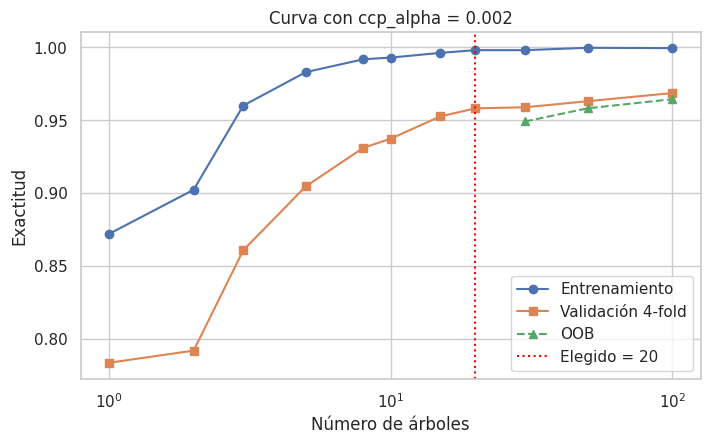

In [11]:
rows = []
for n in [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 100]:
    rf = RandomForestClassifier(n_estimators=n, ccp_alpha=A_OPT, random_state=SEED)
    r = cross_validate(rf, X_train, y_train, cv=cv, return_train_score=True, n_jobs=-1)
    oob = np.nan
    if n >= 30:
        oob = RandomForestClassifier(n_estimators=n, ccp_alpha=A_OPT, oob_score=True,
                                     random_state=SEED).fit(X_train, y_train).oob_score_
    rows.append((n, r["train_score"].mean(), r["test_score"].mean(), oob))
df_c = pd.DataFrame(rows, columns=["n_estimators", "train", "val", "oob"])
display(df_c.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(df_c.n_estimators, df_c.train, "o-", label="Entrenamiento")
plt.plot(df_c.n_estimators, df_c.val, "s-", label="Validación 4-fold")
plt.plot(df_c.n_estimators, df_c.oob, "^--", label="OOB")
plt.axvline(N_OPT, color="red", ls=":", label=f"Elegido = {N_OPT}")
plt.xscale("log"); plt.xlabel("Número de árboles"); plt.ylabel("Exactitud")
plt.title(f"Curva con ccp_alpha = {A_OPT}"); plt.legend(); plt.show()

## 7. Evaluación final en el conjunto de prueba (20 %)
Se reentrena el modelo elegido con todo el 80 % de entrenamiento y se compara contra el modelo base (100 árboles sin poda) y contra la configuración de mayor exactitud de validación.

,Modelo,Árboles,Nodos/árbol,Exactitud train,Exactitud test
0,"Base (100 árboles, sin poda)",100,340.02,1.0000,0.9611
1,Mejor val. de la rejilla,100,340.02,1.0000,0.9611
2,"ELEGIDO (20 árboles, ccp_alpha=0.002)",20,175.00,0.9979,0.9472


              precision    recall  f1-score   support

           0     0.9459    0.9722    0.9589        36
           1     0.8919    0.9167    0.9041        36
           2     0.9714    0.9714    0.9714        35
           3     0.9730    0.9730    0.9730        37
           4     1.0000    1.0000    1.0000        36
           5     0.9487    1.0000    0.9737        37
           6     1.0000    0.9444    0.9714        36
           7     0.9459    0.9722    0.9589        36
           8     0.8485    0.8000    0.8235        35
           9     0.9429    0.9167    0.9296        36

    accuracy                         0.9472       360
   macro avg     0.9468    0.9467    0.9465       360
weighted avg     0.9471    0.9472    0.9469       360



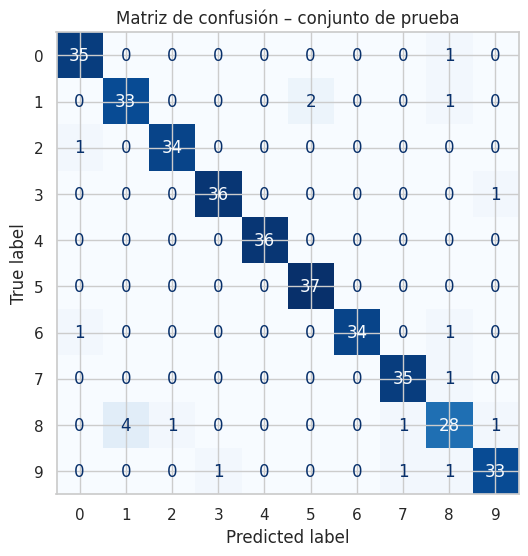

In [12]:
final = RandomForestClassifier(n_estimators=N_OPT, ccp_alpha=A_OPT, random_state=SEED).fit(X_train, y_train)
base = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_train, y_train)
mejor = RandomForestClassifier(n_estimators=int(best.n_estimators), ccp_alpha=float(best.ccp_alpha),
                               random_state=SEED).fit(X_train, y_train)

def nodes(m): return np.mean([t.tree_.node_count for t in m.estimators_])
comp = pd.DataFrame({
    "Modelo": ["Base (100 árboles, sin poda)", "Mejor val. de la rejilla", f"ELEGIDO ({N_OPT} árboles, ccp_alpha={A_OPT})"],
    "Árboles": [100, int(best.n_estimators), N_OPT],
    "Nodos/árbol": [nodes(base), nodes(mejor), nodes(final)],
    "Exactitud train": [accuracy_score(y_train, m.predict(X_train)) for m in (base, mejor, final)],
    "Exactitud test": [accuracy_score(y_test, m.predict(X_test)) for m in (base, mejor, final)],
}).round(4)
display(comp)

y_pred = final.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión – conjunto de prueba"); plt.show()

## 8. Conclusiones

* **Número de árboles.** La exactitud de validación crece rápido con los primeros árboles y se estabiliza en una meseta; pasar de ese punto solo aumenta el costo computacional. El modelo elegido usa el menor número de árboles cuya validación está dentro de 1.5 pp del mejor resultado (ver sección 6, con análisis de sensibilidad a la tolerancia).
* **Estrategia de poda.** Se usó **poda por costo-complejidad (`ccp_alpha`)**: se minimiza $R(T)+\alpha|T|$ en cada árbol, de modo que se eliminan las ramas que aportan poca reducción de impureza por hoja adicional. Se examinó primero el camino de poda de un árbol individual (impureza vs. alpha) y luego se validó con 4-fold dentro del bosque. Un `ccp_alpha` pequeño reduce drásticamente el tamaño de los árboles casi sin perder exactitud; valores grandes producen sub-ajuste (la exactitud cae). Se contrastó con la pre-poda (`max_depth`, `min_samples_leaf`).
* **Over-fitting.** Se controló con (i) validación cruzada de 4 pliegues, (ii) la brecha train–validación, (iii) la curva de validación/OOB estable al aumentar los árboles y (iv) un conjunto de prueba nunca usado en la selección, cuyo resultado es consistente con la validación.
* **Resultado.** El modelo final es más pequeño (menos árboles y menos nodos por árbol) que el bosque base y mantiene un desempeño muy cercano en prueba (el costo de reducir ~5x los árboles y ~2x los nodos es de pocos puntos porcentuales; ver tabla de la sección 7).